# Decision tree and random forest: a visual comparison

Learning aid for section C, not part of the hand-in. Run from inside `handin-titanic/visuals/`, after `clean.py`.

Everything here uses the **training set only**, so the test set stays untouched for section D. This notebook uses unscaled `Age` and `Fare`, so the split rules read in years and pounds. Trees compare one feature to a cut-off at a time, so scaling does not change them.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

SURVIVED, DIED, NEUTRAL = "#2a78d6", "#eb6834", "#f0efec"
INK, MUTED = "#0b0b0b", "#52514e"
PROBABILITY = LinearSegmentedColormap.from_list("probability", [DIED, NEUTRAL, SURVIVED])
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": MUTED,
                     "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

# Same split as clean.py, but before scaling.
df = pd.read_csv("../data/titanic_800_model.csv")
train, _ = train_test_split(df, test_size=0.2, stratify=df["Survived"], random_state=42)
train = train.copy()
train["Age"] = train["Age"].fillna(train["Age"].median())
X = train.drop(columns="Survived")
y = train["Survived"]

X2 = train[["Age", "Fare"]].to_numpy()
y2 = y.to_numpy()
x_range = (X2[:, 0].min() - 2, X2[:, 0].max() + 2)
y_range = (-5, np.percentile(X2[:, 1], 97))
xx, yy = np.meshgrid(np.linspace(*x_range, 400), np.linspace(*y_range, 400))
grid = np.c_[xx.ravel(), yy.ravel()]


def draw(ax, model, title):
    # Shade the model's survival probability and put the passengers on top.
    probabilities = model.predict_proba(grid)[:, 1].reshape(xx.shape)
    ax.contourf(xx, yy, probabilities, levels=np.linspace(0, 1, 21), cmap=PROBABILITY, alpha=0.75)
    ax.contour(xx, yy, probabilities, levels=[0.5], colors=INK, linewidths=1.2)
    ax.scatter(X2[y2 == 1, 0], X2[y2 == 1, 1], s=12, c=SURVIVED, marker="o", edgecolor="#fcfcfb", linewidth=0.4, label="Survived")
    ax.scatter(X2[y2 == 0, 0], X2[y2 == 0, 1], s=12, c=DIED, marker="s", edgecolor="#fcfcfb", linewidth=0.4, label="Died")
    ax.set_title(title, loc="left", color=INK)
    ax.set_xlim(x_range)
    ax.set_ylim(y_range)

## 1. A decision tree on your real features

Read it from the top. Each box asks one yes/no question: left is yes, right is no. `gini` is how mixed the box is (0 = all one class, 0.5 = a 50/50 mix). `samples` is how many passengers reach the box, and `value` is [died, survived].

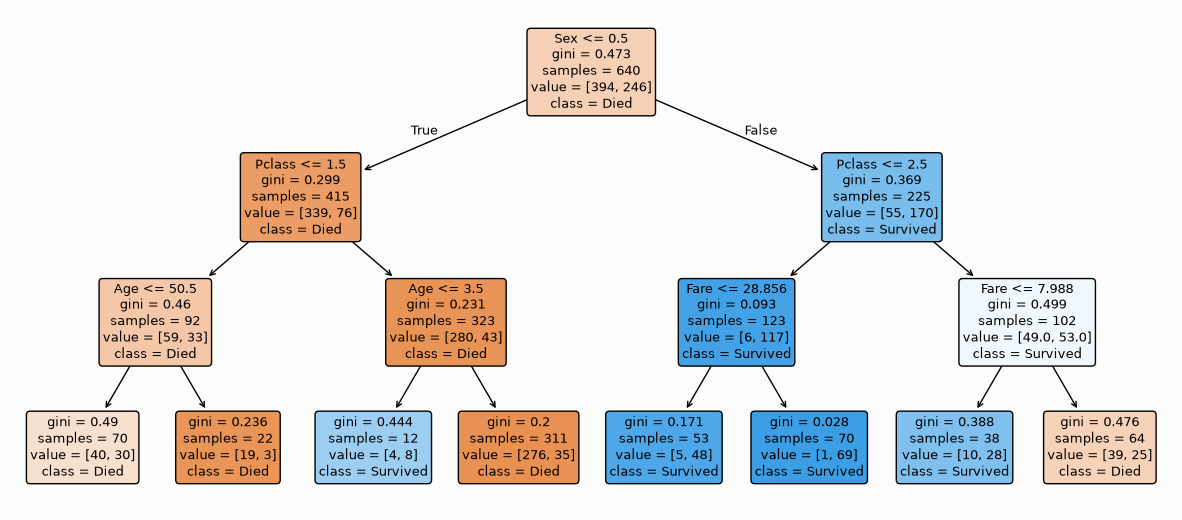

In [2]:
tree = DecisionTreeClassifier(max_depth=3, random_state=1).fit(X, y)
fig, ax = plt.subplots(figsize=(15, 6.5))
plot_tree(tree, feature_names=list(X.columns), class_names=["Died", "Survived"], filled=True, rounded=True, fontsize=9, ax=ax)
plt.show()

## 2. Depth controls overfitting

Same two features, `Age` and `Fare`, for illustration only. Trees cut along one feature at a time, so the regions are boxes.

- **Left:** a shallow tree finds broad patterns.
- **Right:** with no depth limit, the tree carves tiny boxes around single passengers. That is overfitting (memorising the training data).

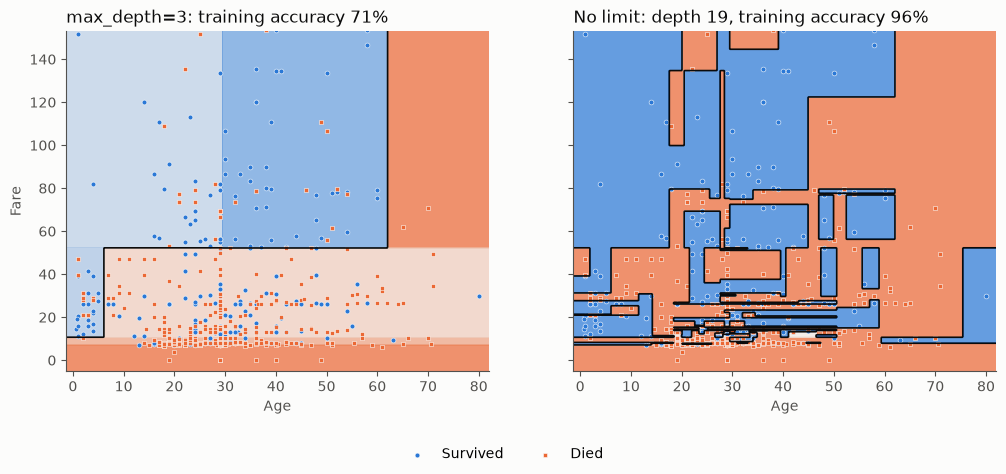

In [3]:
shallow = DecisionTreeClassifier(max_depth=3, random_state=1).fit(X2, y2)
deep = DecisionTreeClassifier(random_state=1).fit(X2, y2)
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
draw(left, shallow, f"max_depth=3: training accuracy {shallow.score(X2, y2):.0%}")
draw(right, deep, f"No limit: depth {deep.get_depth()}, training accuracy {deep.score(X2, y2):.0%}")
left.set_ylabel("Fare")
for ax in (left, right):
    ax.set_xlabel("Age")
fig.subplots_adjust(bottom=0.2)
fig.legend(*left.get_legend_handles_labels(), loc="lower center", ncol=2, frameon=False)
plt.show()

## 3. From one tree to a forest

The first three panels are trees trained on different bootstrap samples (random draws of passengers, with repeats), which is what the course calls bagging. Small changes in the data give visibly different trees, the weakness the course names.

The fourth panel is a forest of 100 such trees. It averages their probabilities (soft voting), so the individual quirks tend to cancel out.

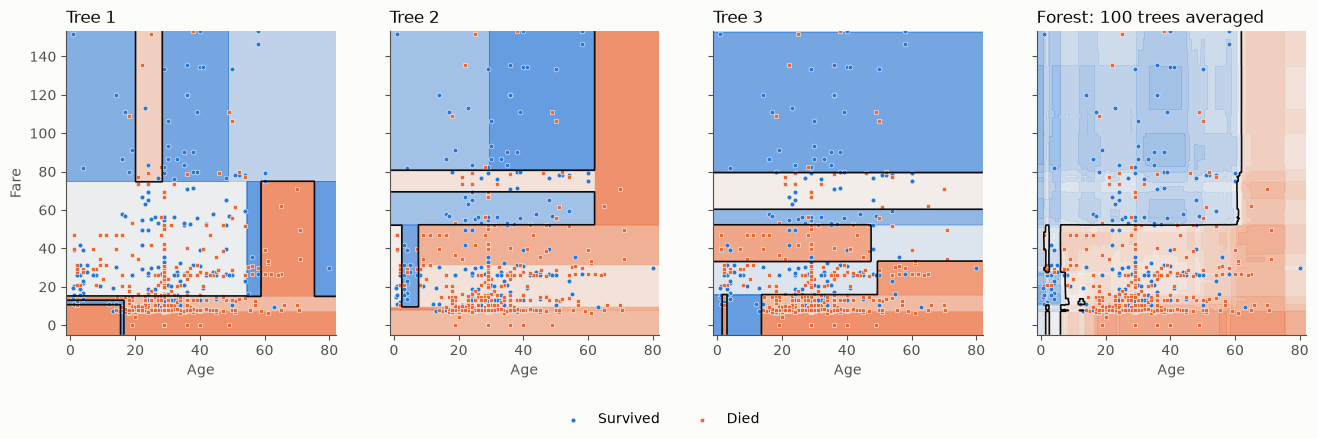

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4.6), sharey=True)
rng = np.random.default_rng(1)
for number, ax in enumerate(axes[:3], start=1):
    rows = rng.integers(0, len(X2), len(X2))
    single = DecisionTreeClassifier(max_depth=4, random_state=number).fit(X2[rows], y2[rows])
    draw(ax, single, f"Tree {number}")
forest2 = RandomForestClassifier(n_estimators=100, max_depth=4, random_state=1).fit(X2, y2)
draw(axes[3], forest2, "Forest: 100 trees averaged")
axes[0].set_ylabel("Fare")
for ax in axes:
    ax.set_xlabel("Age")
fig.subplots_adjust(bottom=0.22)
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=2, frameon=False)
plt.show()

## 4. The two main parameters, on all your features

Cross-validation (5-fold) trains on four fifths of the training set and scores on the last fifth, five times over. It estimates performance on unseen passengers without touching the test set. These are the kind of experiments section E asks for, but the final numbers must still come from the test set.

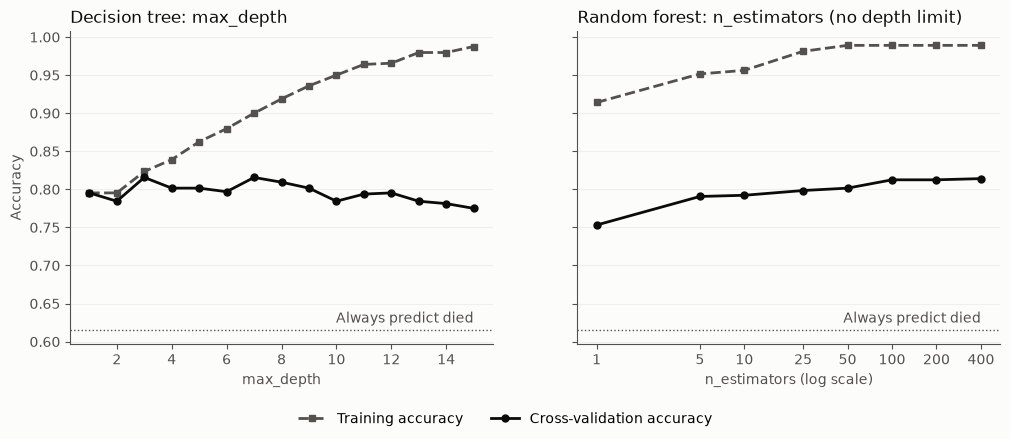

Always predict died: 0.616
Tree CV by depth:   {1: np.float64(0.795), 2: np.float64(0.784), 3: np.float64(0.816), 4: np.float64(0.802), 5: np.float64(0.802), 6: np.float64(0.797), 7: np.float64(0.816), 8: np.float64(0.809), 9: np.float64(0.802), 10: np.float64(0.784), 11: np.float64(0.794), 12: np.float64(0.795), 13: np.float64(0.784), 14: np.float64(0.781), 15: np.float64(0.775)}
Forest CV by trees: {1: np.float64(0.753), 5: np.float64(0.791), 10: np.float64(0.792), 25: np.float64(0.798), 50: np.float64(0.802), 100: np.float64(0.812), 200: np.float64(0.812), 400: np.float64(0.814)}


In [5]:
baseline = 1 - y.mean()
depths = list(range(1, 16))
tree_train = [DecisionTreeClassifier(max_depth=d, random_state=1).fit(X, y).score(X, y) for d in depths]
tree_cv = [cross_val_score(DecisionTreeClassifier(max_depth=d, random_state=1), X, y, cv=5).mean() for d in depths]
sizes = [1, 5, 10, 25, 50, 100, 200, 400]
forest_train = [RandomForestClassifier(n_estimators=n, random_state=1).fit(X, y).score(X, y) for n in sizes]
forest_cv = [cross_val_score(RandomForestClassifier(n_estimators=n, random_state=1), X, y, cv=5).mean() for n in sizes]

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for ax, xs, on_train, on_cv in ((left, depths, tree_train, tree_cv), (right, sizes, forest_train, forest_cv)):
    ax.plot(xs, on_train, color=MUTED, linewidth=2, linestyle="--", marker="s", markersize=5, label="Training accuracy")
    ax.plot(xs, on_cv, color=INK, linewidth=2, marker="o", markersize=5, label="Cross-validation accuracy")
    ax.axhline(baseline, color=MUTED, linewidth=1, linestyle=":")
    ax.text(xs[-1], baseline + 0.005, "Always predict died", color=MUTED, ha="right", va="bottom")
    ax.grid(axis="y", color=NEUTRAL)
left.set_title("Decision tree: max_depth", loc="left", color=INK)
left.set_xlabel("max_depth")
left.set_ylabel("Accuracy")
right.set_title("Random forest: n_estimators (no depth limit)", loc="left", color=INK)
right.set_xlabel("n_estimators (log scale)")
right.set_xscale("log")
right.set_xticks(sizes, [str(n) for n in sizes])
right.minorticks_off()
fig.subplots_adjust(bottom=0.2)
fig.legend(*left.get_legend_handles_labels(), loc="lower center", ncol=2, frameon=False)
plt.show()

print(f"Always predict died: {baseline:.3f}")
print("Tree CV by depth:  ", {d: round(s, 3) for d, s in zip(depths, tree_cv)})
print("Forest CV by trees:", {n: round(s, 3) for n, s in zip(sizes, forest_cv)})